## Libraries

In [5]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols


## hente stored variabler

In [6]:
%store -r df
df = df

%store -r numeric_columns
numeric_columns = numeric_columns

%store -r cat_columns
cat_columns = cat_columns


# Analysis 

## Numerical data

In [7]:
def kde_plot(x):
    plt.figure(figsize=(12, 3))
    sns.distplot(df[x], kde_kws={"lw" : 5}, hist_kws = {"alpha": 0.25})
    sns.despine(left=True)


    mean = df[x].mean()
    median = df[x].median()

    plt.axvline(mean, color='r', linestyle='--')
    plt.axvline(median, color='g', linestyle='-')
    plt.xlabel('')
    plt.ylabel('')

    return plt.show()


## Sjekke median og avg for årstall

### average er rød og median er grønn

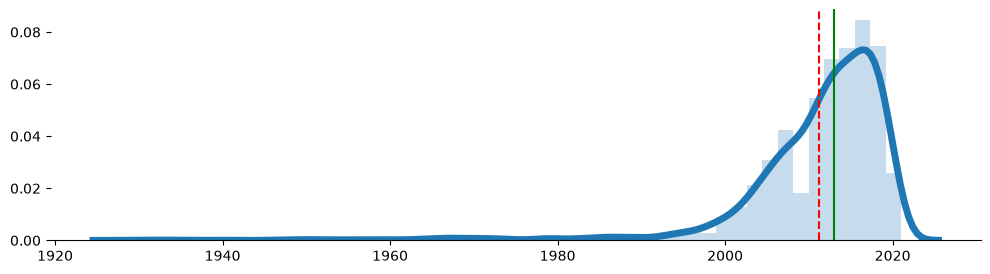

In [8]:
kde_plot(numeric_columns[1])

## Sjekke median og avg for odometer

har også cappet på 400k odonmeter

### y-aksen er density


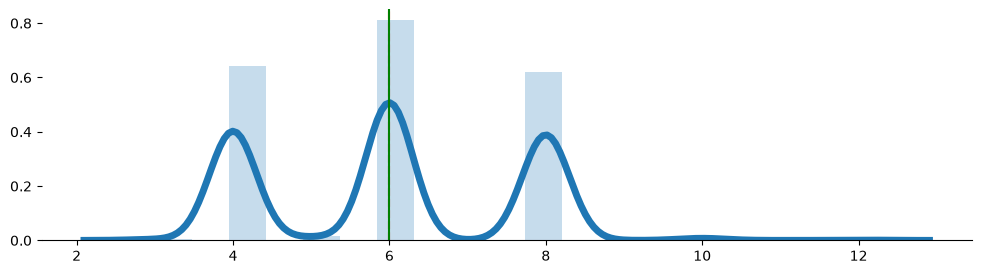

In [9]:
kde_plot(numeric_columns[2])

# Odometer

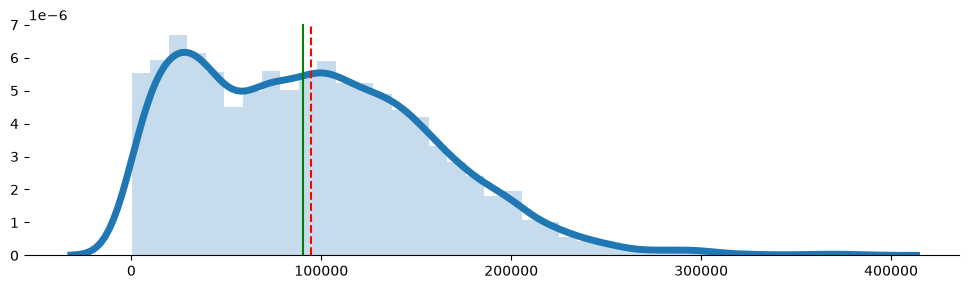

In [10]:
kde_plot(numeric_columns[3])

# Kategorisk data

Hvilke kategori som blir repitert mest

In [11]:
for col in cat_columns[:6]:
    print(f"{col} -> {df[col].mode()[0]}")

region -> columbus
manufacturer -> ford
model -> f-150
condition -> unknown
fuel -> gas
title_status -> clean


# Korrelasjon analysis

se på forskjellen mellom ulike faktorer

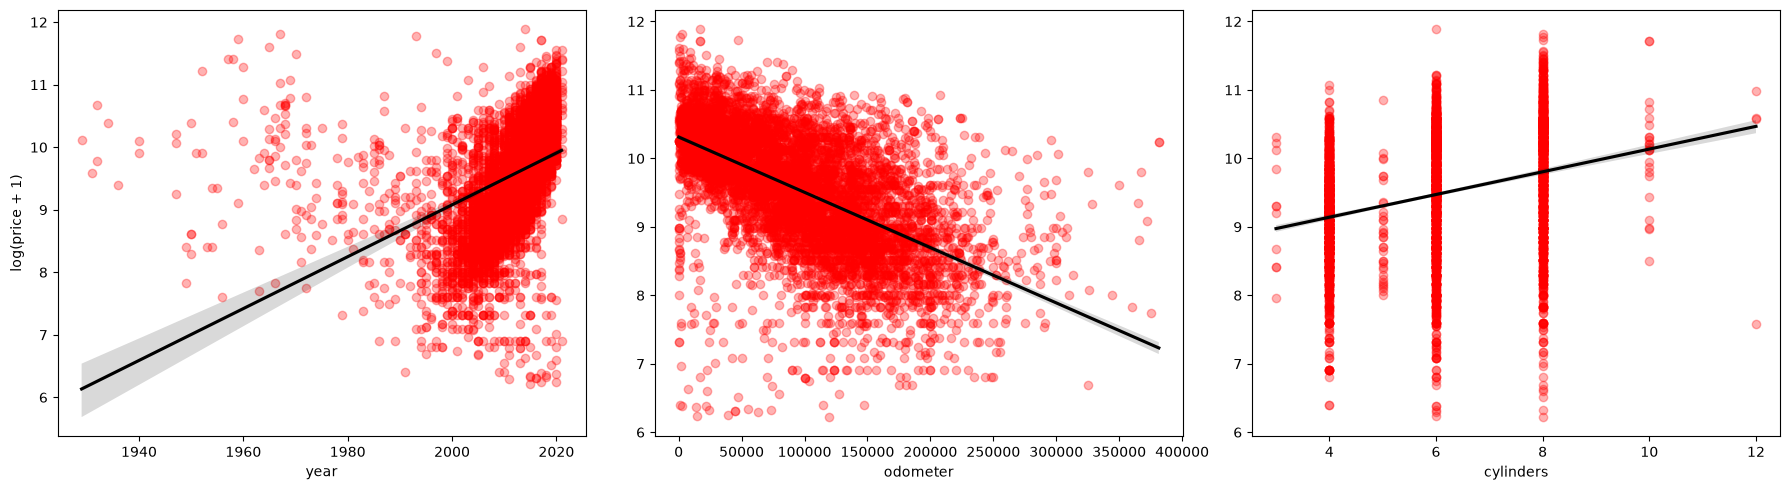

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cols_to_plot = ['year', 'odometer', 'cylinders']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes = axes.ravel()

for i, col in enumerate(cols_to_plot):
    sns.regplot(x=col,
                y=np.log1p(df['price']),  # Logger pris her
                data=df,
                ax=axes[i],
                scatter_kws={'color': 'red', 'alpha': 0.3}, # Alpha gjør punktene litt gjennomsiktige siden det blir mange oppå hverandre
                line_kws={'color': 'black'})   
    
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('log(price + 1)' if i == 0 else '')

plt.tight_layout()
plt.show()

 # Sjekke med heatmap

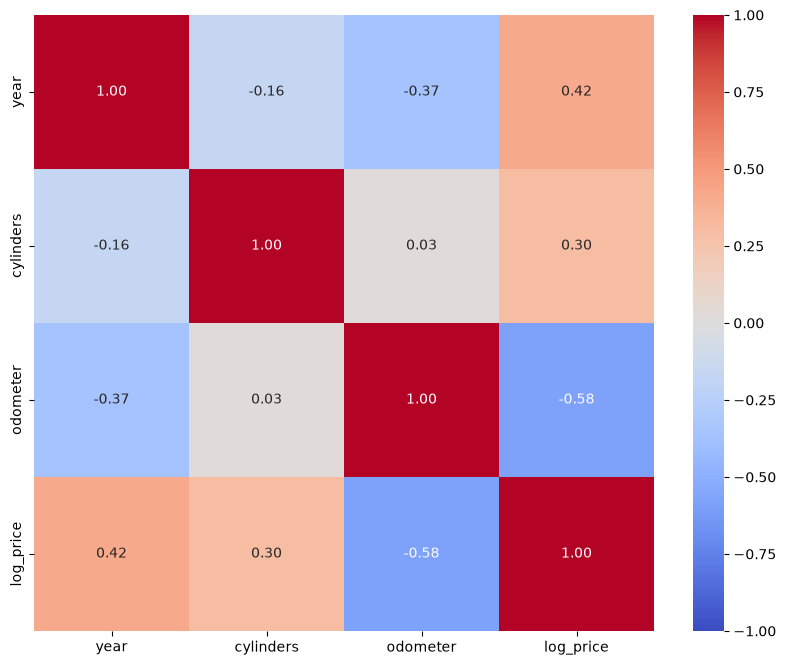

In [13]:
import numpy as np

# Lager en midlertidig kolonne for log-pris
df['log_price'] = np.log1p(df['price'])

# Velg ut kolonnene du vil ha med i matrisen (bytt ut 'price' med 'log_price')
cols_for_corr = ['year', 'cylinders', 'odometer', 'log_price']
pearson_cor = df[cols_for_corr].corr(method='pearson')

plt.figure(figsize=(10, 8))
sns.heatmap(pearson_cor,
            vmin=-1,
            vmax=1,
            cmap='coolwarm',
            annot=True,
            fmt='.2f')
plt.show()

# Fjern den midlertidige kolonnen igjen etterpå hvis du ikke vil ha den i hoveddatasettet
df.drop(columns=['log_price'], inplace=True)

### Nyere bil, høyere antall sylindere og lavere km avstand påvirker prisen

# kategorisk data

### se hva som har mest påvirkning på pris. da må vi finne signifikansen til kategoriene. benytter en ANOVA test for å sammenligne

In [14]:
import numpy as np
from scipy import stats

# 1. Sjekk prisfordelingen
print(df['price'].describe())

# 2. Fjern urealistiske priser (tilpass grensene til datasettet)
df = df[(df['price'] > 500) & (df['price'] < 150_000)].copy()

# 3. Lag log-pris
df['log_price'] = np.log1p(df['price'])

# 4. Rask ANOVA uten OLS
def fast_anova(df, col, target='log_price', min_n=5):
    d = df[[col, target]].dropna()
    d = d[d.groupby(col)[target].transform('count') >= min_n]
    g = d.groupby(col)[target].agg(['count', 'mean'])
    grand = d[target].mean()
    ssb = (g['count'] * (g['mean'] - grand) ** 2).sum()
    sst = ((d[target] - grand) ** 2).sum()
    k, n = len(g), len(d)
    msw = (sst - ssb) / (n - k)
    f = (ssb / (k - 1)) / msw
    omega2 = (ssb - (k - 1) * msw) / (sst + msw)
    return stats.f.sf(f, k - 1, n - k), ssb / sst, omega2, k, n

cat_columns = ['transmission', 'drive', 'fuel', 'type', 'paint_color',
               'condition', 'title_status', 'model', 'region', 'manufacturer']

for c in cat_columns:
    p, eta2, om2, k, n = fast_anova(df, c)
    print(f'{c}: k={k}, n={n}, eta²={eta2:.3f}, omega²={om2:.3f}')

count      7031.000000
mean      19314.104395
std       14955.140115
min         502.000000
25%        7900.000000
50%       15750.000000
75%       27946.000000
max      145000.000000
Name: price, dtype: float64
transmission: k=4, n=7031, eta²=0.098, omega²=0.097
drive: k=4, n=7031, eta²=0.065, omega²=0.065
fuel: k=6, n=7031, eta²=0.088, omega²=0.087
type: k=14, n=7031, eta²=0.122, omega²=0.120
paint_color: k=13, n=7031, eta²=0.040, omega²=0.038
condition: k=7, n=7031, eta²=0.082, omega²=0.081
title_status: k=6, n=7029, eta²=0.017, omega²=0.016
model: k=260, n=3581, eta²=0.395, omega²=0.348
region: k=287, n=6784, eta²=0.084, omega²=0.043
manufacturer: k=37, n=7028, eta²=0.098, omega²=0.094


k= antall grupper. n = antall observasjoner. Eta-kvadrat.  Hvor stor andel av den totale prisvariansen i datasettet som kan forklares av denne kolonnen. Verdien ligger mellom 0 og 1. At model har eta = 0.55 $ betyr at bilmodellen alene forklarer over 50 % av variasjonen i bilprisene. Omega kvadrant fikser svakhetene til eta med at den stiger ved flere grupper


### Modell dominerer med condition, transmission, manufactuer, drive og fuel utgjør en merkbar forskjell sammen

### paint colour har for lav forklaringskraft = n^2 = 0,040 så kan droppe den
Title status kan ha verdier som er lurt å ha med slik som bilkrasjet bil osv

In [15]:
# Dropp farge siden den har lav forklaringskraft
df = df.drop(columns=['paint_color'], errors='ignore')

# Sjekke hvilke objekt i kategoriene påvirker mest

In [16]:
def mean_pairwise(cat_var):
    agg_df = df.groupby(cat_var).agg(
        count=('price', 'count'),
        mean_price=('price', 'mean'),
        median_price=('price', 'median'),
        mean_log=('log_price', 'mean')
    )
    return agg_df.sort_values(by='mean_log', ascending=False).head(5)

cat_columns = ['transmission', 'drive', 'fuel', 'type', 'condition', 'manufacturer']

for c in cat_columns:
    if c in df.columns:
        print(f"Topp 5 for {c}:")
        display(mean_pairwise(c))
        print("\n" + "="*40 + "\n")

Topp 5 for transmission:


,count,mean_price,median_price,mean_log
transmission,,,,
other,1084,28274.604244,28590.0,10.169833
unknown,21,23824.000000,23990.0,9.942041
automatic,5500,17826.481273,13200.0,9.447667
manual,426,15497.291080,10486.0,9.227960




Topp 5 for drive:


,count,mean_price,median_price,mean_log
drive,,,,
4wd,2191,24142.611136,20995.0,9.811832
rwd,1009,20938.096135,18590.0,9.650987
unknown,2056,18725.177043,14989.0,9.485702
fwd,1775,13112.960000,10988.0,9.232669




Topp 5 for fuel:


...

,count,mean_price,median_price,mean_log
type,,,,
pickup,752,29227.476064,28990.0,10.108432
other,332,28138.530120,28590.0,10.057974
offroad,7,31400.000000,18000.0,10.029635
truck,614,26593.964169,24625.0,9.895093
convertible,127,22488.259843,17995.0,9.701440




Topp 5 for condition:


,count,mean_price,median_price,mean_log
condition,,,,
new,13,34266.538462,22985.0,10.084389
good,2157,21026.465925,19990.0,9.671678
unknown,2669,20906.887598,16777.0,9.623112
like new,374,19718.227273,14060.0,9.559796
excellent,1671,15710.536804,11995.0,9.391585




Topp 5 for manufacturer:


,count,mean_price,median_price,mean_log
manufacturer,,,,
ferrari,1,99999.000000,99999.0,11.512925
tesla,21,40609.476190,38990.0,10.595363
alfa-romeo,14,29857.357143,29945.0,10.272463
porsche,30,31858.600000,31450.0,10.249777
ram,304,32232.098684,31990.0,10.207388


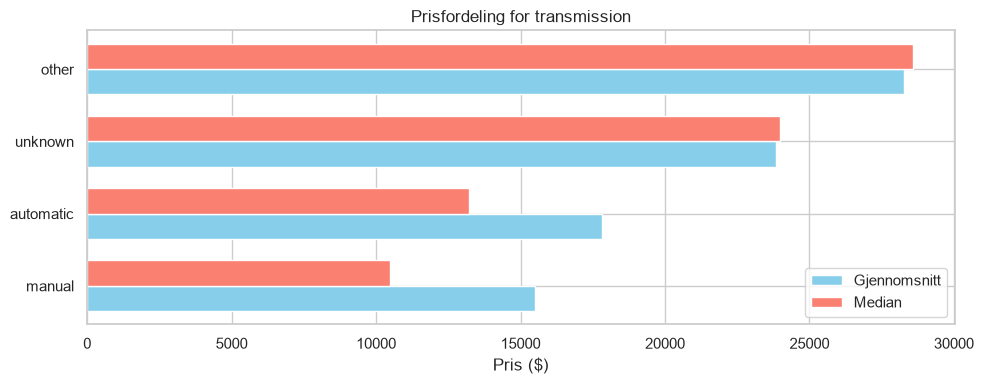

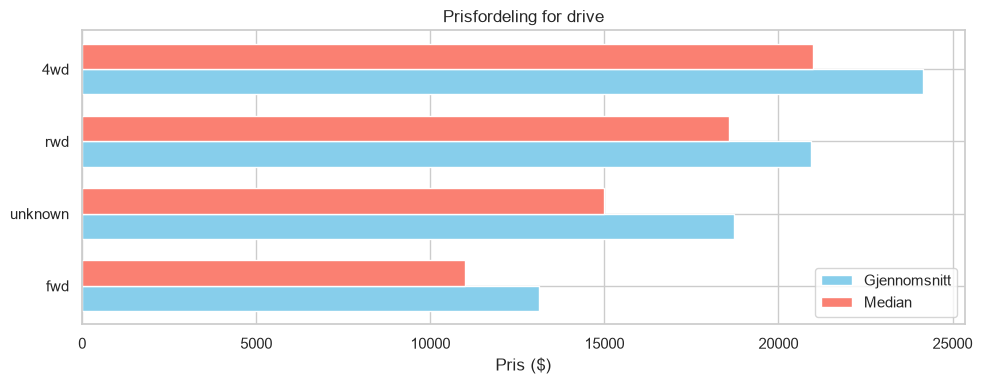

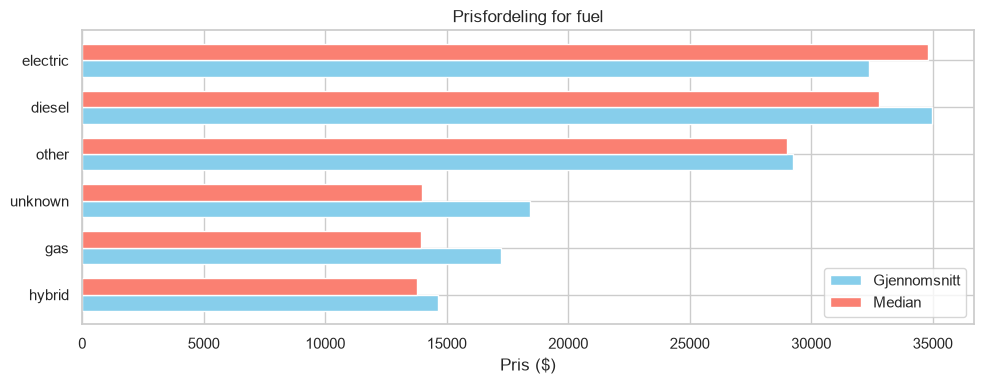

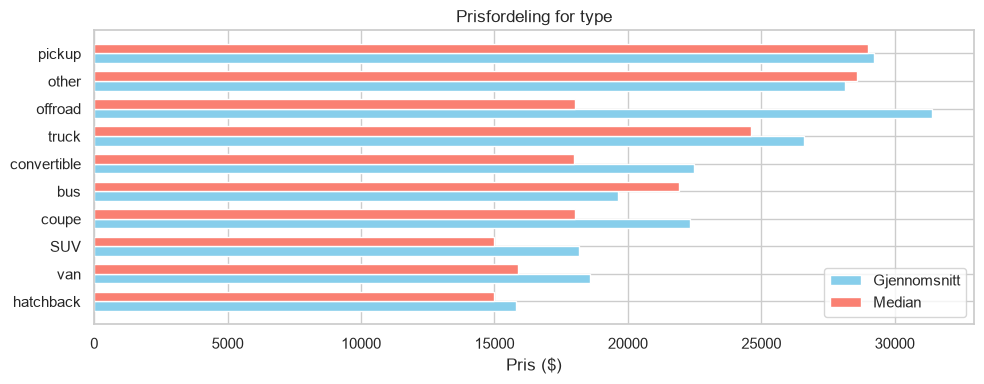

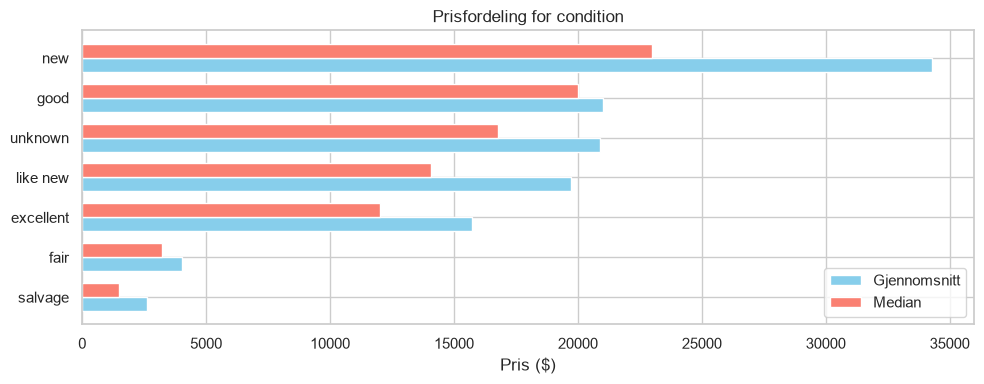

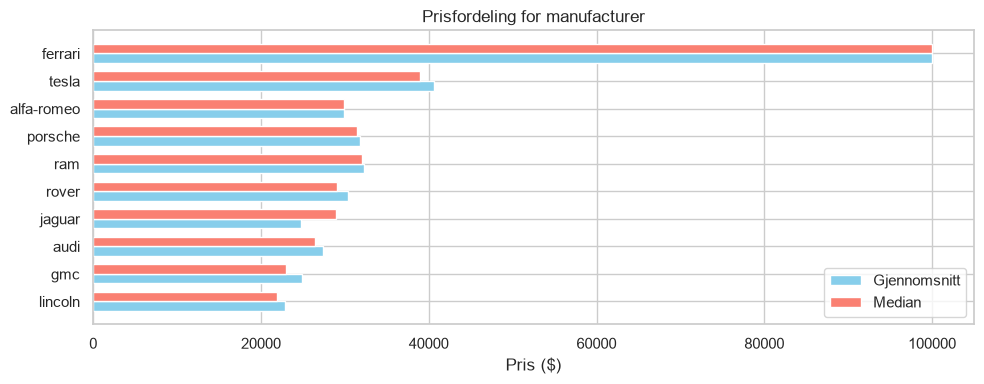

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

cat_columns = ['transmission', 'drive', 'fuel', 'type', 'condition', 'manufacturer']

for c in cat_columns:
    if c in df.columns:
        agg_df = df.groupby(c).agg(
            mean_price=('price', 'mean'),
            median_price=('price', 'median'),
            mean_log=('log_price', 'mean')
        ).sort_values(by='mean_log', ascending=True).tail(10)
        
        fig, ax = plt.subplots(figsize=(10, max(4, len(agg_df) * 0.4)))
        
        width = 0.35
        x = range(len(agg_df))
        
        ax.barh([i - width/2 for i in x], agg_df['mean_price'], width, label='Gjennomsnitt', color='skyblue')
        ax.barh([i + width/2 for i in x], agg_df['median_price'], width, label='Median', color='salmon')
        
        ax.set_yticks(x)
        ax.set_yticklabels(agg_df.index)
        ax.set_xlabel('Pris ($)')
        ax.set_title(f'Prisfordeling for {c}')
        ax.legend()
        
        plt.tight_layout()
        plt.show()